# PfDHFR Network Construction — all three variants

Builds **occupancy**, **DCCM** and **hybrid** networks for WT, S99N and I155L.

| Symbol | Shape | Object |
|---|---|---|
| `X` | (T, N, 3) | Cα coordinates |
| `D(t)` | (N, N) | distances, per frame |
| `S` | (N, N) | sequence-separation mask |
| `C(t)` | (N, N) | contact indicator, per frame |
| `W` | (N, N) | **occupancy matrix** |
| `R` | (N, N) | **dynamic cross-correlation matrix** |
| `A`, `Ã` | (N, N) | adjacency / weighted adjacency |
| `G` | — | **network** (occupancy / DCCM / hybrid) |

Every parameter is justified in section 1.1 with its source.

---
## 1. Configuration

Everything tunable lives here. Nothing below needs editing for a normal run.

In [ ]:
# ---- which variants to build ----
VARIANTS = ["WT", "S99N", "I155L"]

# ---- paths ----
ROOT   = "/Users/Ritwik/Desktop/Projects/graph_analysis"
OUTDIR = f"{ROOT}/analysis/networks"
FIGDIR = f"{ROOT}/figures"

# ---- per-variant file locations and timestep ----
# frames_per_window is DERIVED from dt_ps, not hardcoded:
# I155L runs at 10 ps, so a 100 ns window is 10,000 frames there, not 5,000.
VARIANT_SPEC = {
    "WT":    {"top": "analysis/rmsd_rmsf/WT/frame0.gro",
              "traj": "data/raw/WT/WT_md_fit.xtc",   "dt_ps": 20},
    "S99N":  {"top": "analysis/rmsd_rmsf/S99N/frame0.gro",
              "traj": "data/raw/S99N/md_fit.xtc",    "dt_ps": 20},
    "I155L": {"top": "analysis/rmsd_rmsf/I155L/frame0.gro",
              "traj": "data/raw/I155L/md_fit.xtc",   "dt_ps": 10},
}

# ---- network parameters (justified in 1.1) ----
N_RES      = 219        # N
CUTOFF_LO  = 4.0        # d_lo, angstrom
CUTOFF_HI  = 8.0        # d_hi, angstrom
MIN_SEP    = 2          # s   : exclude |i-j| <= 2
THRESHOLD  = 0.50       # theta : occupancy threshold (occupancy graph)
THETA_HYB  = 0.75       # theta_h : occupancy threshold (hybrid graph, Sethi convention)
CORR_CUTS  = {"loose": 0.3, "tight": 0.5}   # c : |R| cutoffs, both built
WINDOW_NS  = 100        # window length
N_WINDOWS  = 10         # windows per trajectory

# ---- residue sets of interest (construct numbering, 1-219) ----
RIDGE     = [48, 52, 95, 137, 139, 140, 160, 164, 165, 168, 169]
MUT_SITES = [99, 155]
ACTIVE_SITE = []        # TODO: fill in from mentor  -> blocks Act III
NADPH_SITE  = []        # TODO: fill in from mentor  -> blocks Act III

### 1.1 Parameter justification

| Parameter | Value | Basis |
|---|---|---|
| Node representation | Cα, one per residue | Standard coarse-graining for residue interaction networks (RINs); the Cα is the one atom every residue shares in the same structural role. [1,2] |
| `CUTOFF_HI` | 8.0 Å | The standard upper cutoff in protein contact network analysis. Geometrically it is roughly two peptide-bond lengths, an upper bound on biologically meaningful inter-residue interaction. [1,2,3] |
| `CUTOFF_LO` | 4.0 Å | **From the mentor's tracker.** Intended to exclude trivially-touching backbone neighbours. It does exclude i,i+1 (Cα–Cα ≈ 3.8 Å) but *not* i,i+2 or i,i+3 — hence the separate mask below. Keeping it costs nothing once the mask is in place. |
| `MIN_SEP` | 2 (keep \|i−j\| > 2) | Matches Bio3D's `cmap(..., scut=3)` default, which excludes pairs with sequence separation below 3. [4] Sequence neighbours are close regardless of fold, so including them records backbone geometry rather than tertiary structure, and inflates clustering coefficient and modularity — both Objective 1 metrics. |
| `THETA_HYB` | 0.75 | Sethi et al. (PNAS 2009) require a contact to be present in **>75% of frames** before an edge is drawn. [5,6] This is the origin of the tracker's `min_occ = 0.75`. |
| `THRESHOLD` | 0.50 | **Our choice, not from literature.** At 0.75 the standalone Cα occupancy network fragmented (30 residues dropped out, including ridge candidates). 0.50 was selected from a threshold sweep showing smooth, cliff-free variation in edge count from 0.25 to 0.90 (section 7). Note Sethi's 0.75 applies to a *heavy-atom* contact definition at 4.5 Å, which is stricter in space but more permissive in time than a Cα 4–8 Å band — the two thresholds are not directly transferable. |
| `CORR_CUTS` | 0.3 and 0.5 | **Both built; choice deferred to results.** The tracker attributes 0.3 to Sethi et al. 2009 — see the correction below. |
| Window | 100 ns | **From the mentor's tracker.** Convergence of the correlation estimate at this length is tested in section 10 before any DCCM result is interpreted. |

#### Correction to the tracker's citation

The tracker states the 0.3 correlation cutoff is *"literature-informed (Sethi et al. 2009)"*. That attribution is wrong in a way worth knowing:

> *"In the method described in PNAS 2009, the network edges are completely determined by contact maps."* — Grant lab (Bio3D), on `cna()` correlation cutoffs [4]

In Sethi et al., **correlation never decides whether an edge exists**. Edges come from the contact map (heavy atoms within 4.5 Å for >75% of frames). Correlation only sets the edge *weight*, as `-log|C_ij|`. [5,6]

The `cutoff.cij = 0.3` number is a **Bio3D `cna()` convention**, and the Grant lab is explicit that it is system-dependent:

> *"the cutoff for correlation varies from system to system, and even between different methods for the same system."* [4]

So 0.3 is a starting point to be tuned, not a value inherited from a paper. Section 10 scans it empirically.

#### Edge weight direction

Sethi's `-log|C_ij|` is a **distance**: smaller means more strongly coupled, so `shortest_path` and `betweenness_centrality` behave correctly. [5,7]

Several NetworkX routines — betweenness among them — interpret an edge `weight` attribute as a distance to minimise. Occupancy and |R| are *strengths*. Passing them directly inverts the meaning. Every graph built below therefore carries **two** attributes:

- `weight` — the raw strength (occupancy, or |R|)
- `distance` — `-log(strength)`, for path-based measures

#### References

1. Residue interaction networks, 8 Å Cα convention — https://arxiv.org/pdf/2508.01501
2. Network measures for protein folding state discrimination (PCN at 8 Å) — https://arxiv.org/pdf/1512.01126
3. Silveira et al., *Protein cutoff scanning*, Proteins — 7.0 Å identified as the lower bound at which contact sets become complete; 8 Å sits safely above it — https://www2.dcc.ufmg.br/laboratorios/lbs/papers/proteins.pdf
4. Bio3D `cmap(dcut=4.5, scut=3, pcut=0.75)` and `cna(cutoff.cij=...)` guidance — https://bitbucket.org/Grantlab/bio3d/issues/240/ and .../485/
5. Sethi, Eargle, Black & Luthey-Schulten, *Dynamical networks in tRNA:protein complexes*, PNAS 106:6620–6625 (2009), doi:10.1073/pnas.0810961106
6. Dynamical Network Analysis documentation (4.5 Å heavy-atom, >75% frames) — https://dynamical-network-analysis.readthedocs.io/en/stable/Introduction.html
7. Atilgan et al., *Small-world communication of residues* — degree-preserving rewiring null model that preserves (i,i+1) chain connectivity — https://arxiv.org/pdf/cond-mat/0308006

Items 1–7 were checked against the sources. Anything marked **"from the mentor's tracker"** is taken from `Project Tracker - Graph Analysis.docx` and has not been independently verified.

In [8]:
import os, time, pickle
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import mdtraj as md
from scipy.stats import pearsonr

os.makedirs(OUTDIR, exist_ok=True)
os.makedirs(FIGDIR, exist_ok=True)

def savefig(section, name):
    '''Save the current figure into figures/<section>/<name>.png.'''
    d = f"{FIGDIR}/{section}"
    os.makedirs(d, exist_ok=True)
    path = f"{d}/{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"  figure -> {path}")

def frames_per_window(dt_ps, window_ns=WINDOW_NS):
    '''100 ns window -> how many frames, given this variant's timestep.'''
    return int(window_ns * 1000 / dt_ps)


# ---- shared plotting helpers: every matrix stage is shown for every variant ----

def grid(nrows, ncols, h=4.0, w=4.3):
    '''Always-2D axes array, so ax[row][col] works even with one variant.'''
    fig, ax = plt.subplots(nrows, ncols, figsize=(w*ncols, h*nrows), squeeze=False)
    return fig, ax


def heat(ax, M, title, cmap="viridis", vmin=None, vmax=None, cbar=True, label=""):
    '''One matrix as a heatmap, axes labelled in residue numbers (1-N).'''
    im = ax.imshow(M, cmap=cmap, origin="lower", vmin=vmin, vmax=vmax,
                   extent=[1, M.shape[0], 1, M.shape[1]])
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("residue"); ax.set_ylabel("residue")
    if cbar:
        plt.colorbar(im, ax=ax, shrink=0.75, label=label)
    return im

for v in VARIANTS:
    spec = VARIANT_SPEC[v]
    print(f"{v:6s} dt={spec['dt_ps']:3d} ps  ->  "
          f"{frames_per_window(spec['dt_ps']):5d} frames per {WINDOW_NS} ns window")

WT     dt= 20 ps  ->   5000 frames per 100 ns window
S99N   dt= 20 ps  ->   5000 frames per 100 ns window
I155L  dt= 10 ps  ->  10000 frames per 100 ns window


---
## 2. `X` — the coordinate tensor

Reads each trajectory and keeps only the 219 Cα atoms, discarding water and everything
else. Result has shape **(T, N, 3)**: frames × residues × (x, y, z).

Cached to `.npy` — the slow read off the external drive happens once per variant.
Re-running afterwards loads from SSD in under a second.

Expect roughly 2–3 min for WT and S99N, 4–6 min for I155L (double the frames).

In [ ]:
def extract_ca(variant, force=False):
    '''Return (xyz_nm, resnums). Cached on disk.'''
    spec    = VARIANT_SPEC[variant]
    xyz_out = f"{OUTDIR}/{variant}_ca_xyz.npy"
    res_out = f"{OUTDIR}/{variant}_resnums.npy"

    if os.path.exists(xyz_out) and not force:
        xyz, resnums = np.load(xyz_out), np.load(res_out)
        print(f"{variant}: cached  {xyz.shape}")
        return xyz, resnums

    top_path  = f"{ROOT}/{spec['top']}"
    traj_path = f"{ROOT}/{spec['traj']}"
    for p in (top_path, traj_path):
        if not os.path.exists(p):
            raise FileNotFoundError(f"{variant}: missing {p}  (external drive mounted?)")

    top = md.load_topology(top_path)
    ca  = top.select("protein and name CA")
    if len(ca) != N_RES:
        raise ValueError(f"{variant}: found {len(ca)} CA atoms, expected {N_RES}")
    resnums = np.array([top.atom(i).residue.resSeq for i in ca])

    t0, chunks = time.time(), []
    for chunk in md.iterload(traj_path, chunk=2000, top=top, atom_indices=ca):
        chunks.append(chunk.xyz)
        print(f"  {variant}: {sum(c.shape[0] for c in chunks)} frames", end="\r", flush=True)
    xyz = np.concatenate(chunks).astype(np.float32)

    np.save(xyz_out, xyz); np.save(res_out, resnums)
    print(f"\n{variant}: {xyz.shape}  resSeq {resnums[0]}-{resnums[-1]}  "
          f"{time.time()-t0:.0f}s  {xyz.nbytes/1e6:.0f} MB")
    return xyz, resnums


coords = {v: extract_ca(v) for v in VARIANTS}
print()
for v, (xyz, rn) in coords.items():
    print(f"{v:6s} {str(xyz.shape):20s} {xyz.nbytes/1e6:6.0f} MB  "
          f"{xyz.shape[0]*VARIANT_SPEC[v]['dt_ps']/1000:.0f} ns total")

---
## 3. Sequence check

Confirms each variant carries the mutation it claims. A mislabelled trajectory would
invalidate every cross-variant comparison and is otherwise completely invisible.

Expected: **SER→ASN at resSeq 99** and **ILE→LEU at resSeq 155**, one difference each.

Note the two numbering conventions in play:
- resSeq 99 = canonical **S108N**, resSeq 155 = canonical **I164L** (a −9 construct offset)
- the ridge candidates and wet-lab targets (M95I, F164A) are already in **construct**
  numbering — MET sits at resSeq 95, PHE at resSeq 164 — so they need **no shift**

In [6]:
def residue_names(variant):
    top = md.load_topology(f"{ROOT}/{VARIANT_SPEC[variant]['top']}")
    return [(r.resSeq, r.name) for r in top.residues][:N_RES]

seqs = {v: residue_names(v) for v in VARIANTS}

if "WT" in VARIANTS:
    wt_seq = seqs["WT"]
    wt_map = dict(wt_seq)
    print("WT identity checks (ridge / wet-lab numbering):")
    for r in (95, 99, 155, 164):
        print(f"  resSeq {r:3d}: {wt_map[r]}")
    print()
    for v in VARIANTS:
        if v == "WT":
            continue
        diffs = [(a[0], a[1], b[1]) for a, b in zip(wt_seq, seqs[v]) if a[1] != b[1]]
        status = "OK" if len(diffs) == 1 else "CHECK THIS"
        print(f"{v:6s} vs WT: {len(diffs)} difference(s)  [{status}]  "
              + ", ".join(f"resSeq {r}: {w}->{m}" for r, w, m in diffs))
else:
    for v in VARIANTS:
        print(v, dict(seqs[v]))

WT identity checks (ridge / wet-lab numbering):
  resSeq  95: MET
  resSeq  99: SER
  resSeq 155: ILE
  resSeq 164: PHE

S99N   vs WT: 1 difference(s)  [OK]  resSeq 99: SER->ASN
I155L  vs WT: 1 difference(s)  [OK]  resSeq 155: ILE->LEU


---
## 4. `S` — the sequence-separation mask

Residues adjacent in the chain are close regardless of how the protein folds, so
counting them as contacts records backbone geometry, not fold architecture.

A distance floor alone does not remove them. Consecutive Cα sit at ~3.8 Å and are
excluded by the 4 Å cutoff, but in an α-helix the i,i+2 and i,i+3 separations are
~5.4 Å and ~5.0 Å — both inside the contact band, both passing the distance filter
unchallenged.

$$S_{ij} = \begin{cases} 1 & |i-j| > s \\ 0 & \text{otherwise}\end{cases}$$

`s = 2` matches Bio3D's `cmap(scut=3)` default. [ref 4]

all pairs        : 23871
allowed by mask  : 23436  (98.2%)
excluded by mask : 435
  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/04_mask/mask_S.png


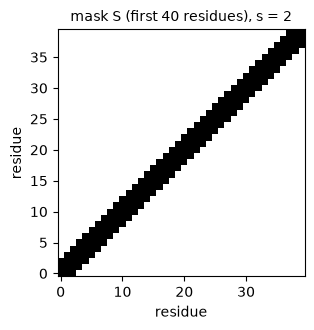

In [9]:
idx  = np.arange(N_RES)
SEP  = np.abs(np.subtract.outer(idx, idx))      # |i-j| for every pair
MASK = SEP > MIN_SEP                            # S

iu = np.triu_indices(N_RES, k=1)                # each pair once
N_POSSIBLE = int(MASK[iu].sum())
print(f"all pairs        : {len(iu[0])}")
print(f"allowed by mask  : {N_POSSIBLE}  ({100*N_POSSIBLE/len(iu[0]):.1f}%)")
print(f"excluded by mask : {len(iu[0]) - N_POSSIBLE}")

fig, ax = plt.subplots(figsize=(4, 3.4))
ax.imshow(MASK[:40, :40], cmap="Greys_r", origin="lower")
ax.set_title(f"mask S (first 40 residues), s = {MIN_SEP}", fontsize=10)
ax.set_xlabel("residue"); ax.set_ylabel("residue")
plt.tight_layout(); savefig("04_mask", "mask_S"); plt.show()

---
## 5. `D(t)` and `C(t)` — one frame at a time

**`D(t)`** holds the Euclidean distance between every pair of Cα in a single frame.

**`C(t)`** is the binary verdict for that frame: 1 if the pair is inside the contact
band *and* allowed by the mask, 0 otherwise.

Neither is stored. Both are computed inside the loop and discarded — only the running
count survives. Shown here on a single frame to make the objects concrete.

WT     frame 0 | shape (219, 219) | symmetric True | Ca(1)-Ca(2) = 3.76 A | contacts  516
S99N   frame 0 | shape (219, 219) | symmetric True | Ca(1)-Ca(2) = 3.94 A | contacts  517
I155L  frame 0 | shape (219, 219) | symmetric True | Ca(1)-Ca(2) = 3.97 A | contacts  514

(the Ca(1)-Ca(2) column is why d_lo = 4.0 A already excludes i,i+1)
  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/05_distance_contact/D_C_frame0_all.png


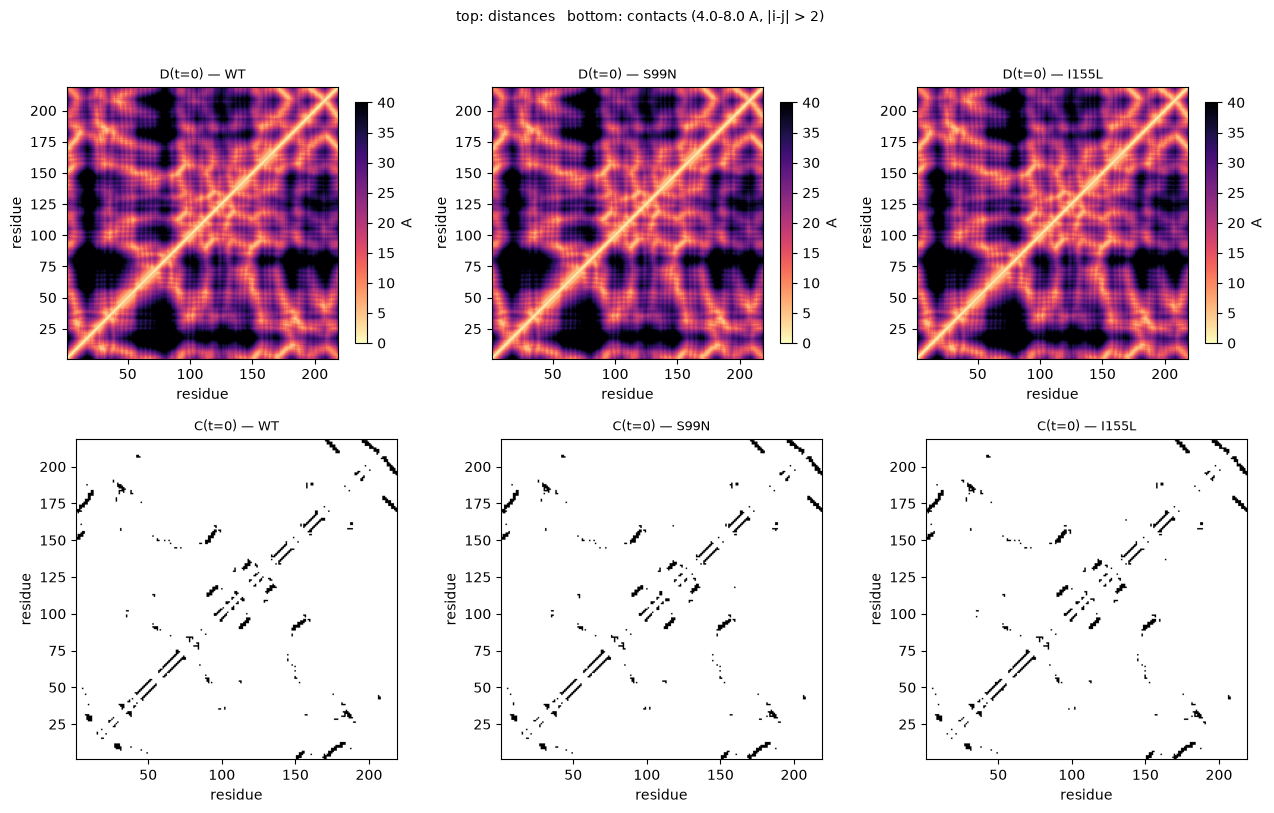

In [10]:
Dmats, Cmats = {}, {}
for v in VARIANTS:
    xyz, _ = coords[v]
    fr = xyz[0] * 10.0                                        # nm -> angstrom
    D  = np.linalg.norm(fr[:, None, :] - fr[None, :, :], axis=-1)
    C  = (D >= CUTOFF_LO) & (D <= CUTOFF_HI) & MASK
    Dmats[v], Cmats[v] = D, C
    print(f"{v:6s} frame 0 | shape {D.shape} | symmetric {np.allclose(D, D.T)} | "
          f"Ca(1)-Ca(2) = {D[0,1]:.2f} A | contacts {int(C[iu].sum()):4d}")
print(f"\n(the Ca(1)-Ca(2) column is why d_lo = {CUTOFF_LO} A already excludes i,i+1)")

fig, ax = grid(2, len(VARIANTS))
for c, v in enumerate(VARIANTS):
    heat(ax[0][c], Dmats[v], f"D(t=0) — {v}", cmap="magma_r", vmax=40, label="A")
    heat(ax[1][c], Cmats[v].astype(int), f"C(t=0) — {v}", cmap="Greys", cbar=False)
fig.suptitle(f"top: distances   bottom: contacts ({CUTOFF_LO}-{CUTOFF_HI} A, "
             f"|i-j| > {MIN_SEP})", y=1.01, fontsize=10)
plt.tight_layout(); savefig("05_distance_contact", "D_C_frame0_all"); plt.show()

---
## 6. `W` — the occupancy matrix

Average the per-frame verdicts over the window. Each entry is the **fraction of the
window** during which that pair was in contact.

$$W_{ij} = \frac{1}{T}\sum_{t=1}^{T} C_{ij}(t)$$

Binary in, continuous out. This is what separates the approach from building a network
off a single structure: a contact present 95% of the time and one present 30% of the
time become different objects.

**Why not average the coordinates first?** The contact test is non-linear in position.
A pair at 4 Å half the time and 12 Å the other half averages to ~8 Å and registers as a
contact — though it is in contact only half the time. Worse, averaging can place an atom
where it never was: a side chain alternating between two rotamers averages to the empty
space between them. Occupancy takes every contact decision on a configuration the system
genuinely occupied, and averages only the verdicts.

In [11]:
def occupancy_matrix(xyz_window, cutoff_lo=CUTOFF_LO, cutoff_hi=CUTOFF_HI, mask=MASK):
    '''W for one window. xyz_window: (T, N, 3) in nm.'''
    xa = xyz_window * 10.0
    counts = np.zeros((xa.shape[1], xa.shape[1]))
    for fr in xa:
        d = np.linalg.norm(fr[:, None, :] - fr[None, :, :], axis=-1)
        counts += (d >= cutoff_lo) & (d <= cutoff_hi) & mask
    return counts / xa.shape[0]


def split_windows(xyz, dt_ps, n_windows=N_WINDOWS):
    '''Slice into n_windows of WINDOW_NS each, using this variant's own timestep.'''
    w = frames_per_window(dt_ps)
    if xyz.shape[0] < n_windows * w:
        raise ValueError(f"trajectory has {xyz.shape[0]} frames, "
                         f"need {n_windows*w} for {n_windows} x {WINDOW_NS} ns")
    return [xyz[k*w:(k+1)*w] for k in range(n_windows)]

WT     10 windows x 5000 frames | W in 6s | range [0.00, 1.00] | distinct 474  <- continuous, not binary
S99N   10 windows x 5000 frames | W in 6s | range [0.00, 1.00] | distinct 455  <- continuous, not binary
I155L  10 windows x 10000 frames | W in 11s | range [0.00, 1.00] | distinct 565  <- continuous, not binary
  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/06_occupancy/W_window01_all.png


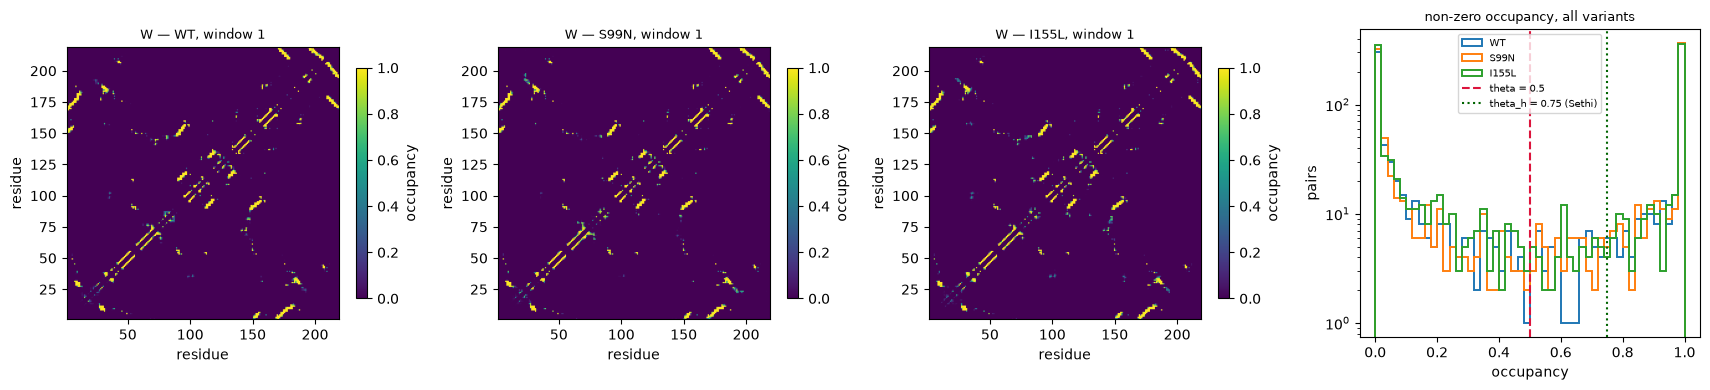

In [12]:
# window 1 of every variant. Cached to disk, so re-running this cell is free.
W1 = {}
for v in VARIANTS:
    cache = f"{OUTDIR}/{v}_W_window01.npy"
    if os.path.exists(cache):
        W1[v] = np.load(cache)
        print(f"{v:6s} cached   range [{W1[v].min():.2f}, {W1[v].max():.2f}]   "
              f"distinct {len(np.unique(W1[v]))}")
        continue
    wins = split_windows(coords[v][0], VARIANT_SPEC[v]["dt_ps"])
    t0 = time.time()
    W1[v] = occupancy_matrix(wins[0])
    np.save(cache, W1[v])
    print(f"{v:6s} {len(wins)} windows x {wins[0].shape[0]} frames | "
          f"W in {time.time()-t0:.0f}s | range [{W1[v].min():.2f}, {W1[v].max():.2f}] | "
          f"distinct {len(np.unique(W1[v]))}  <- continuous, not binary")

fig, ax = grid(1, len(VARIANTS) + 1)
for c, v in enumerate(VARIANTS):
    heat(ax[0][c], W1[v], f"W — {v}, window 1", vmin=0, vmax=1, label="occupancy")
hx = ax[0][len(VARIANTS)]
for v in VARIANTS:
    vals = W1[v][iu]
    hx.hist(vals[vals > 0], bins=50, histtype="step", lw=1.4, label=v)
hx.axvline(THRESHOLD, color="crimson", ls="--", label=f"theta = {THRESHOLD}")
hx.axvline(THETA_HYB, color="darkgreen", ls=":", label=f"theta_h = {THETA_HYB} (Sethi)")
hx.set_yscale("log"); hx.set_xlabel("occupancy"); hx.set_ylabel("pairs")
hx.set_title("non-zero occupancy, all variants", fontsize=9); hx.legend(fontsize=7)
plt.tight_layout(); savefig("06_occupancy", "W_window01_all"); plt.show()

---
## 7. Choosing `theta`

Sweep the threshold and watch how the network responds. A **smooth** curve means the
topology is not an artefact of where the line was drawn — a robustness argument worth
being able to make.

A sharp cliff would mean the opposite, and the threshold would become a parameter to
defend rather than a convenience.


WT window 1
 theta  edges  giant  iso   ridge   mut
  0.90    408    180   35   11/11   2/2
  0.85    432    185   30   11/11   2/2
  0.80    448    188   25   11/11   2/2
  0.75    461    189   24   11/11   2/2
  0.70    473    191   22   11/11   2/2
  0.65    487    193   19   11/11   2/2
  0.60    489    193   19   11/11   2/2
  0.55    500    195   17   11/11   2/2
  0.50    511    197   15   11/11   2/2
  0.45    519    198   11   11/11   2/2
  0.40    529    204   11   11/11   2/2
  0.35    545    205    8   11/11   2/2
  0.30    555    206    5   11/11   2/2
  0.25    567    207    4   11/11   2/2

S99N window 1
 theta  edges  giant  iso   ridge   mut
  0.90    408    183   33   11/11   2/2
  0.85    431    193   26   11/11   2/2
  0.80    444    197   22   11/11   2/2
  0.75    464    203   16   11/11   2/2
  0.70    472    203   16   11/11   2/2
  0.65    482    203   14   11/11   2/2
  0.60    496    206   11   11/11   2/2
  0.55    505    206   11   11/11   2/2
  0.50    52

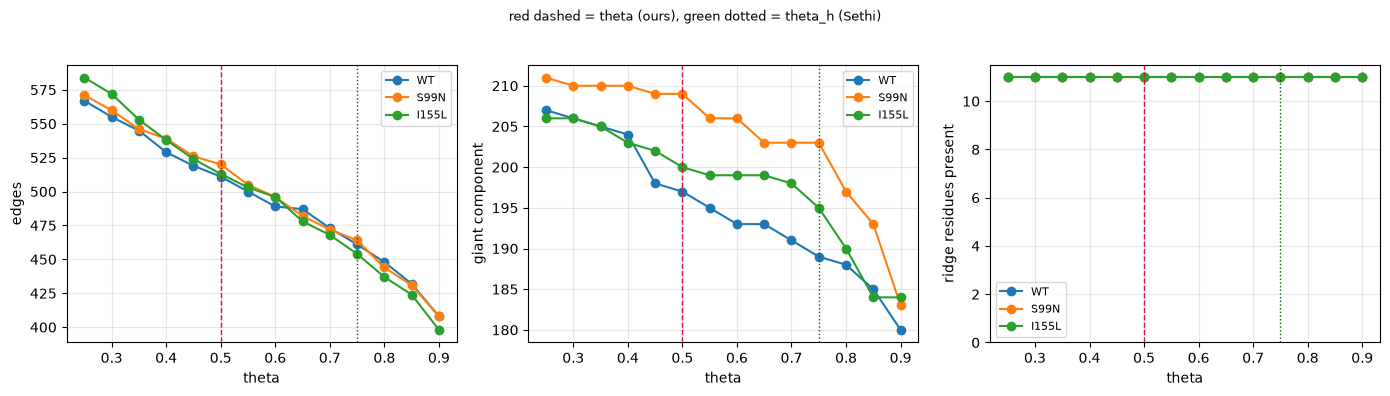

In [13]:
def threshold_scan(W, resnums, thresholds=np.arange(0.90, 0.20, -0.05)):
    rows = []
    for th in thresholds:
        A = (W >= th)
        G = nx.from_numpy_array(np.triu(A, k=1).astype(int))
        G = nx.relabel_nodes(G, {i: int(r) for i, r in enumerate(resnums)})
        giant = len(max(nx.connected_components(G), key=len))
        rows.append({"theta": float(th), "edges": G.number_of_edges(),
                     "giant": giant, "isolated": len(list(nx.isolates(G))),
                     "ridge_in": sum(1 for r in RIDGE if G.degree(r) > 0),
                     "mut_in": sum(1 for r in MUT_SITES if G.degree(r) > 0)})
    return rows

scans = {}
for v in VARIANTS:
    scans[v] = threshold_scan(W1[v], coords[v][1])
    print(f"\n{v} window 1")
    print(f"{'theta':>6} {'edges':>6} {'giant':>6} {'iso':>4} {'ridge':>7} {'mut':>5}")
    for r in scans[v]:
        print(f"{r['theta']:>6.2f} {r['edges']:>6} {r['giant']:>6} {r['isolated']:>4} "
              f"{r['ridge_in']:>4}/11 {r['mut_in']:>3}/2")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for v in VARIANTS:
    th = [r["theta"] for r in scans[v]]
    ax[0].plot(th, [r["edges"] for r in scans[v]], "o-", label=v)
    ax[1].plot(th, [r["giant"] for r in scans[v]], "o-", label=v)
    ax[2].plot(th, [r["ridge_in"] for r in scans[v]], "o-", label=v)
ax[0].set_ylabel("edges"); ax[1].set_ylabel("giant component")
ax[2].set_ylabel("ridge residues present"); ax[2].set_ylim(0, 11.5)
for a in ax:
    a.axvline(THRESHOLD, color="crimson", ls="--", lw=1)
    a.axvline(THETA_HYB, color="darkgreen", ls=":", lw=1)
    a.set_xlabel("theta"); a.grid(alpha=0.3); a.legend(fontsize=8)
fig.suptitle("red dashed = theta (ours), green dotted = theta_h (Sethi)",
             y=1.03, fontsize=9)
plt.tight_layout(); savefig("07_threshold", "threshold_sweep_all"); plt.show()

---
## 8. `A`, `Ã` and the network `G`

Thresholding `W` gives the adjacency matrix. Retaining the occupancy value on surviving
pairs gives the weighted adjacency.

$$A_{ij} = \mathbb{1}[W_{ij} \ge \theta] \qquad \tilde{A} = W \odot A$$

The graph is the same object in network notation. In practice it is built straight from
`W` — `A` and `Ã` are never materialised, though either is recoverable from `G`.

**Node labels are residue numbers**, not array indices, so node 164 is residue 164.

**Two edge attributes.** `weight` is the strength; `distance` is `-log(weight)`, for
path-based measures, following Sethi et al. [ref 5]. Note that an occupancy of exactly
1.00 gives distance 0 — a permanently-formed contact offers no resistance to a path.
That is defensible but worth stating; `1/W` is the alternative if a strictly positive
distance is wanted.

WT     219 nodes,  511 edges | <k>  4.67 | density 0.0214 | A entries [0. 1.] | A~ range [0.50, 1.00]
S99N   219 nodes,  520 edges | <k>  4.75 | density 0.0218 | A entries [0. 1.] | A~ range [0.50, 1.00]
I155L  219 nodes,  513 edges | <k>  4.68 | density 0.0215 | A entries [0. 1.] | A~ range [0.50, 1.00]

A~ is bounded below by theta = 0.5 by construction — thresholding removes the weak entries, it does not rescale the survivors.
  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/08_adjacency/adjacency_all.png


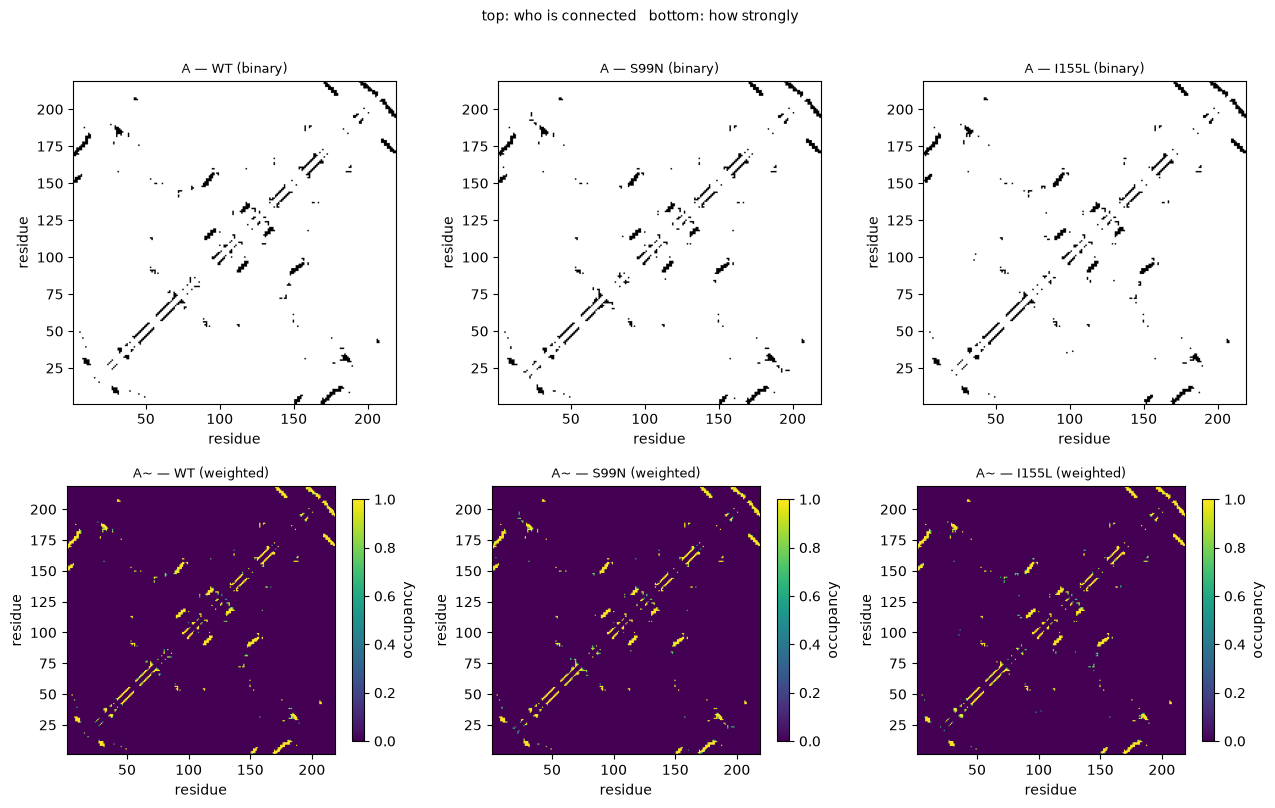

In [14]:
def _add_weighted_edge(G, u, v, strength, extra=None):
    d = -np.log(strength) if strength > 0 else np.inf
    attrs = {"weight": float(strength), "distance": float(d)}
    if extra:
        attrs.update(extra)
    G.add_edge(int(u), int(v), **attrs)


def graph_from_occupancy(W, resnums, theta=THRESHOLD):
    '''G = (V, E, w) from the occupancy matrix.'''
    G = nx.Graph()
    G.add_nodes_from(int(r) for r in resnums)
    for i, j in zip(*np.triu_indices(len(resnums), k=1)):
        if W[i, j] >= theta:
            _add_weighted_edge(G, resnums[i], resnums[j], W[i, j])
    return G


A_bin, A_wgt = {}, {}
for v in VARIANTS:
    G = graph_from_occupancy(W1[v], coords[v][1])
    A_bin[v] = nx.to_numpy_array(G, weight=None)
    A_wgt[v] = nx.to_numpy_array(G, weight="weight")
    nz = A_wgt[v][A_wgt[v] > 0]
    rng_txt = f"[{nz.min():.2f}, {nz.max():.2f}]" if nz.size else "(no edges)"
    print(f"{v:6s} {G.number_of_nodes()} nodes, {G.number_of_edges():4d} edges | "
          f"<k> {2*G.number_of_edges()/N_RES:5.2f} | density {nx.density(G):.4f} | "
          f"A entries {np.unique(A_bin[v])} | A~ range {rng_txt}")
print(f"\nA~ is bounded below by theta = {THRESHOLD} by construction — "
      f"thresholding removes the weak entries, it does not rescale the survivors.")

fig, ax = grid(2, len(VARIANTS))
for c, v in enumerate(VARIANTS):
    heat(ax[0][c], A_bin[v], f"A — {v} (binary)", cmap="Greys", cbar=False)
    heat(ax[1][c], A_wgt[v], f"A~ — {v} (weighted)", cmap="viridis",
         vmin=0, vmax=1, label="occupancy")
fig.suptitle("top: who is connected   bottom: how strongly", y=1.01, fontsize=10)
plt.tight_layout(); savefig("08_adjacency", "adjacency_all"); plt.show()

---
## 9. Occupancy networks — all windows, all variants

Threshold is held fixed across windows **and** variants. Comparison is only meaningful
if the construction is identical everywhere.

Runtime: roughly 1 min per variant for WT/S99N, ~2 min for I155L (double the frames).

In [15]:
def build_occupancy_variant(variant, theta=THRESHOLD, n_windows=N_WINDOWS):
    xyz, resnums = coords[variant]
    dt = VARIANT_SPEC[variant]["dt_ps"]
    wins = split_windows(xyz, dt, n_windows)

    graphs, occs, iso = {}, {}, {}
    print(f"\n{variant}  ({wins[0].shape[0]} frames/window, theta={theta})")
    for k, w in enumerate(wins, start=1):
        W = occupancy_matrix(w)
        G = graph_from_occupancy(W, resnums, theta)
        graphs[k], occs[k] = G, W
        iso[k] = {int(n) for n in nx.isolates(G)}
        giant = len(max(nx.connected_components(G), key=len))
        print(f"  w{k:02d}: {G.number_of_edges():4d} edges  giant {giant:3d}/{N_RES}  "
              f"<k>={2*G.number_of_edges()/N_RES:5.2f}  iso {len(iso[k]):2d}  "
              f"ridge {sum(1 for r in RIDGE if G.degree(r)>0):2d}/11  "
              f"mut {sum(1 for r in MUT_SITES if G.degree(r)>0)}/2")

    always, ever = set.intersection(*iso.values()), set.union(*iso.values())
    print(f"  isolated in ALL windows  ({len(always)}): {sorted(always)}")
    print(f"  isolated in SOME window  ({len(ever-always)}): {sorted(ever-always)}")

    out = f"{OUTDIR}/{variant}_occupancy_graphs.pkl"
    with open(out, "wb") as f:
        pickle.dump({"variant": variant, "graphs": graphs, "occupancy": occs,
                     "resnums": resnums, "theta": theta,
                     "isolated_always": always, "isolated_ever": ever,
                     "params": {"cutoff_lo": CUTOFF_LO, "cutoff_hi": CUTOFF_HI,
                                "min_sep": MIN_SEP, "window_ns": WINDOW_NS,
                                "frames_per_window": wins[0].shape[0],
                                "dt_ps": dt}}, f)
    print(f"  saved -> {out}")
    return graphs, occs


occ_results = {v: build_occupancy_variant(v) for v in VARIANTS}


WT  (5000 frames/window, theta=0.5)
  w01:  511 edges  giant 197/219  <k>= 4.67  iso 15  ridge 11/11  mut 2/2
  w02:  519 edges  giant 208/219  <k>= 4.74  iso 11  ridge 11/11  mut 2/2
  w03:  530 edges  giant 211/219  <k>= 4.84  iso  6  ridge 11/11  mut 2/2
  w04:  530 edges  giant 211/219  <k>= 4.84  iso  6  ridge 11/11  mut 2/2
  w05:  545 edges  giant 215/219  <k>= 4.98  iso  4  ridge 11/11  mut 2/2
  w06:  557 edges  giant 212/219  <k>= 5.09  iso  5  ridge 11/11  mut 2/2
  w07:  537 edges  giant 206/219  <k>= 4.90  iso 11  ridge 11/11  mut 2/2
  w08:  548 edges  giant 209/219  <k>= 5.00  iso  4  ridge 11/11  mut 2/2
  w09:  548 edges  giant 212/219  <k>= 5.00  iso  7  ridge 11/11  mut 2/2
  w10:  544 edges  giant 212/219  <k>= 4.97  iso  5  ridge 11/11  mut 2/2
  isolated in ALL windows  (2): [16, 106]
  isolated in SOME window  (23): [13, 14, 17, 19, 20, 21, 22, 23, 39, 42, 77, 79, 80, 83, 84, 85, 86, 87, 88, 121, 125, 128, 130]
  saved -> /Users/Ritwik/Desktop/Projects/graph_ana

  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/09_occupancy_networks/occupancy_stability_all.png


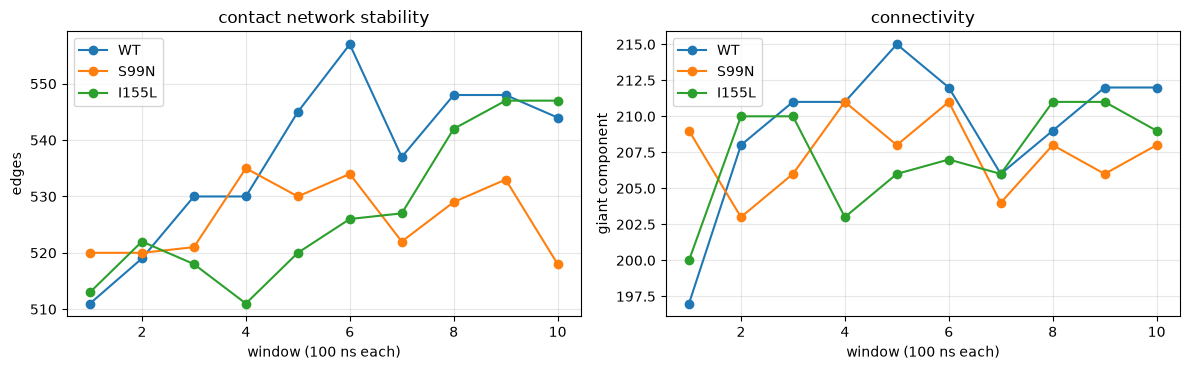

In [16]:
# cross-variant comparison
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ks = range(1, N_WINDOWS+1)
for v in VARIANTS:
    graphs, _ = occ_results[v]
    ax[0].plot(ks, [graphs[k].number_of_edges() for k in ks], "o-", label=v)
    ax[1].plot(ks, [len(max(nx.connected_components(graphs[k]), key=len)) for k in ks],
               "o-", label=v)
ax[0].set_ylabel("edges"); ax[0].set_title("contact network stability")
ax[1].set_ylabel("giant component"); ax[1].set_title("connectivity")
for a in ax:
    a.set_xlabel(f"window ({WINDOW_NS} ns each)"); a.grid(alpha=0.3); a.legend()
plt.tight_layout(); savefig("09_occupancy_networks", "occupancy_stability_all"); plt.show()

---
## 10. `R` — the dynamic cross-correlation matrix

Occupancy asks *do these two residues touch*. The DCCM asks a different question:
*do they move together*.

For each residue, take its displacement from its own mean position per frame — the
**fluctuation**. For every pair, ask whether their fluctuations are synchronised.

$$\langle \mathbf{x}_i \rangle = \frac{1}{T}\sum_t \mathbf{x}_i(t)
\qquad \Delta\mathbf{x}_i(t) = \mathbf{x}_i(t) - \langle\mathbf{x}_i\rangle$$

$$R_{ij} = \frac{\sum_t \Delta\mathbf{x}_i(t)\cdot\Delta\mathbf{x}_j(t)}
{\sqrt{\sum_t \|\Delta\mathbf{x}_i(t)\|^2}\;\sqrt{\sum_t \|\Delta\mathbf{x}_j(t)\|^2}}
\qquad R \in [-1,1]^{N\times N}$$

This is the Pearson correlation applied to vector-valued data. The inner `·` contracts
x, y, z to a scalar **before** the pairing — this is the *scalar* DCCM (N×N), not the
3N×3N covariance matrix that `gmx covar` diagonalises for PCA.

| R | meaning |
|---|---|
| +1 | fluctuations exactly parallel — the residues move as a rigid unit |
| 0 | motion uncoupled |
| −1 | exactly antiparallel — motion in opposition, as across a hinge |

**Why this is worth computing separately from contacts.** Two residues can be strongly
correlated without ever touching — opposite ends of a domain moving as a unit, 30 Å
apart. That is exactly the long-range coupling a compensatory ridge would be expected
to show, and a contact map cannot see it.

### Two caveats, both of which the diagnostics below test

**1. Mean subtraction assumes global motion is already removed.** The fluctuation
removes each residue's own average position, but not coherent rotation of the whole
body. If the protein drifts or rotates within a window, that motion enters every
$\Delta\mathbf{x}_i$ identically and pushes `R` toward +1 everywhere. The trajectories
are fitted (`md_fit.xtc`), so this should be handled — but fitting was done against one
global reference, not per window, so residual drift is plausible.

**2. `T` is not the effective sample size.** Successive MD frames 10–20 ps apart are
strongly autocorrelated, so $T_{\text{eff}} \ll T$. Occupancy is a counting statistic
and tolerates this. Correlation is a second-order statistic and does not.

Section 10.1 tests convergence directly. **Do not interpret any DCCM result before
that test passes.**

In [17]:
def dccm_matrix(xyz_window):
    '''Scalar DCCM R for one window. xyz_window: (T, N, 3).'''
    dr  = xyz_window - xyz_window.mean(axis=0)          # fluctuations
    dot = np.einsum("tik,tjk->ij", dr, dr)              # Sigma_ij, one contraction
    var = np.diagonal(dot)                              # Sigma_ii = T * MSF
    return dot / np.sqrt(np.outer(var, var))            # normalised to [-1, 1]

### 10.1 Convergence test — run this before interpreting anything

Split one window in half and correlate the two DCCM estimates against each other. Two
halves of the same window are sampling the same conformational state, so they should
agree.

| half-vs-half `r` | reading |
|---|---|
| > 0.85 | converged — window-to-window variation is real and interpretable |
| 0.6 – 0.85 | marginal — prefer longer windows for the DCCM |
| < 0.6 | **not converged** — do not interpret the DCCM at this window length |

The adjacent-window correlations below are a second check. Real conformational change
persists across neighbouring windows; an estimator that is simply noisy will not.

In [18]:
print(f"{'variant':8s} {'half-vs-half r':>15s}   adjacent-window r")
print("-" * 70)
conv = {}
for v in VARIANTS:
    xyz, _ = coords[v]
    wins = split_windows(xyz, VARIANT_SPEC[v]["dt_ps"])
    mid  = N_WINDOWS // 2
    w    = wins[mid]
    h    = w.shape[0] // 2
    a, b = dccm_matrix(w[:h]), dccm_matrix(w[h:])
    r_half = pearsonr(a[iu], b[iu])[0]

    mats = {k: dccm_matrix(win) for k, win in enumerate(wins, start=1)}
    adj  = [pearsonr(mats[k][iu], mats[k+1][iu])[0] for k in range(1, N_WINDOWS)]
    conv[v] = {"half": r_half, "adjacent": adj, "matrices": mats}

    verdict = "converged" if r_half > 0.85 else ("marginal" if r_half > 0.6 else "NOT converged")
    print(f"{v:8s} {r_half:15.3f}   " + " ".join(f"{x:.2f}" for x in adj)
          + f"   [{verdict}]")

variant   half-vs-half r   adjacent-window r
----------------------------------------------------------------------
WT                 0.772   0.86 0.82 0.85 0.80 0.84 0.79 0.71 0.84 0.90   [marginal]
S99N               0.869   0.86 0.85 0.90 0.91 0.81 0.80 0.92 0.94 0.83   [converged]
I155L              0.838   0.70 0.73 0.68 0.72 0.80 0.75 0.88 0.86 0.77   [marginal]


  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/10_dccm/dccm_convergence.png


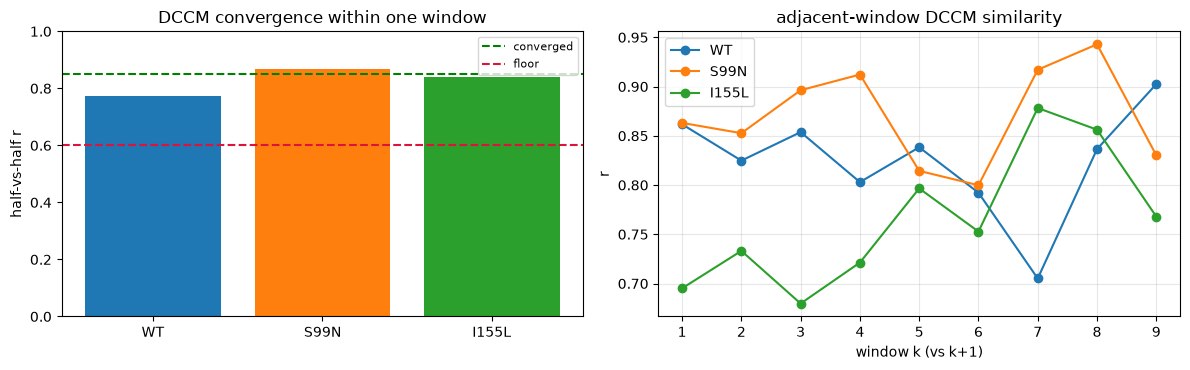

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for v in VARIANTS:
    ax[0].bar(v, conv[v]["half"])
    ax[1].plot(range(1, N_WINDOWS), conv[v]["adjacent"], "o-", label=v)
ax[0].axhline(0.85, color="green", ls="--", label="converged")
ax[0].axhline(0.60, color="crimson", ls="--", label="floor")
ax[0].set_ylim(0, 1); ax[0].set_ylabel("half-vs-half r")
ax[0].set_title("DCCM convergence within one window"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("window k (vs k+1)"); ax[1].set_ylabel("r")
ax[1].set_title("adjacent-window DCCM similarity"); ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); savefig("10_dccm", "dccm_convergence"); plt.show()

### 10.2 Choosing the correlation cutoff `c`

The DCCM is dense by nature: correlation decays slowly with distance in a compact
domain. Betweenness centrality finds bottlenecks — nodes that many shortest paths must
route through. In a graph where nearly everything is directly connected there are few
bottlenecks, and betweenness stops meaning much.

Two competing considerations, and no literature value to settle it (see §1.1):

- **Comparability.** The occupancy network sits at mean degree ~5. A DCCM graph at mean
  degree ~35 is a different kind of object; centralities are not comparable between them.
- **Information.** Cutting the DCCM down to contact-like sparsity may delete exactly the
  long-range coupling that makes it worth computing.

Both cutoffs are built below. The choice is deferred to downstream results rather than
argued in advance.

window 5   (possible pairs after mask: 23436)

WT
 cutoff   edges  density    <k>    neg
    0.3    3823    0.163   34.9   1793
    0.4    1598    0.068   14.6    517
    0.5     659    0.028    6.0     88
    0.6     302    0.013    2.8      6
    0.7      92    0.004    0.8      0
    0.8      14    0.001    0.1      0

S99N
 cutoff   edges  density    <k>    neg
    0.3    2377    0.101   21.7    745
    0.4     959    0.041    8.8     88
    0.5     435    0.019    4.0      3
    0.6     198    0.008    1.8      0
    0.7      40    0.002    0.4      0
    0.8       2    0.000    0.0      0

I155L
 cutoff   edges  density    <k>    neg
    0.3    6044    0.258   55.2   2653
    0.4    3056    0.130   27.9   1069
    0.5    1349    0.058   12.3    257
    0.6     538    0.023    4.9     16
    0.7     234    0.010    2.1      0
    0.8      63    0.003    0.6      0
  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/10_dccm/dccm_matrices_all.png


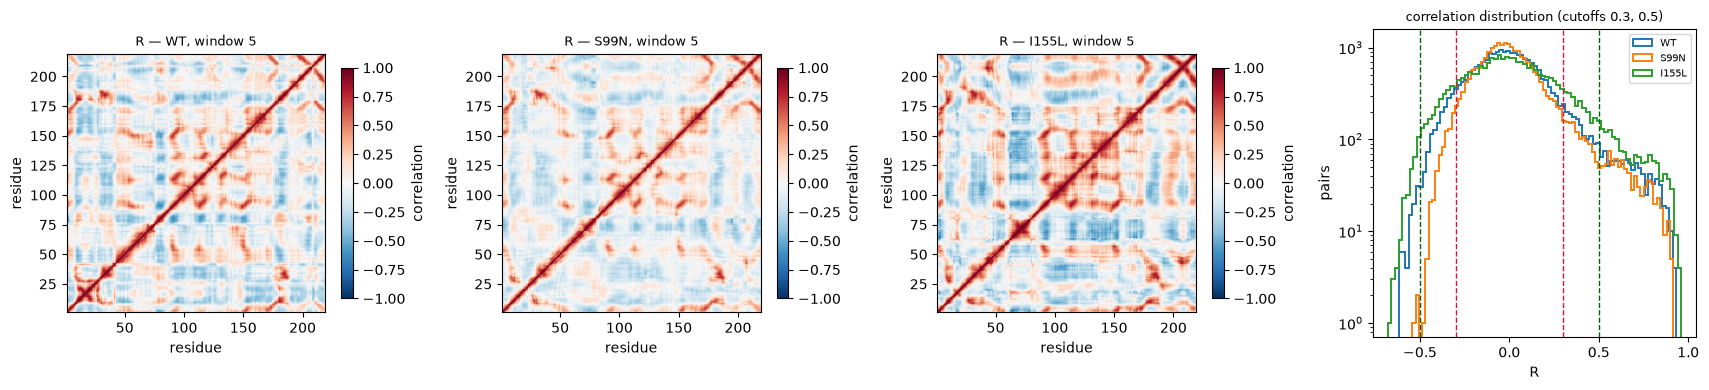

In [20]:
k_mid = N_WINDOWS // 2
Rmid = {v: conv[v]["matrices"][k_mid] for v in VARIANTS}

print(f"window {k_mid}   (possible pairs after mask: {N_POSSIBLE})")
for v in VARIANTS:
    R = Rmid[v]
    print(f"\n{v}")
    print(f"{'cutoff':>7} {'edges':>7} {'density':>8} {'<k>':>6} {'neg':>6}")
    for c in (0.3, 0.4, 0.5, 0.6, 0.7, 0.8):
        A = (np.abs(R) >= c) & MASK
        e   = int(A[iu].sum())
        neg = int(((R < 0) & A)[iu].sum())
        print(f"{c:>7.1f} {e:>7d} {e/N_POSSIBLE:>8.3f} {2*e/N_RES:>6.1f} {neg:>6d}")

fig, ax = grid(1, len(VARIANTS) + 1)
for c, v in enumerate(VARIANTS):
    heat(ax[0][c], Rmid[v], f"R — {v}, window {k_mid}", cmap="RdBu_r",
         vmin=-1, vmax=1, label="correlation")
hx = ax[0][len(VARIANTS)]
for v in VARIANTS:
    hx.hist(Rmid[v][iu], bins=80, histtype="step", lw=1.4, label=v)
for c, col in ((0.3, "crimson"), (0.5, "darkgreen")):
    hx.axvline(c, color=col, ls="--", lw=1); hx.axvline(-c, color=col, ls="--", lw=1)
hx.set_yscale("log"); hx.set_xlabel("R"); hx.set_ylabel("pairs")
hx.set_title("correlation distribution (cutoffs 0.3, 0.5)", fontsize=9)
hx.legend(fontsize=7)
plt.tight_layout(); savefig("10_dccm", "dccm_matrices_all"); plt.show()

### 10.3 Building the DCCM graphs

**The sign is information.** `|R|` is stored as `weight` so the graph is usable, but the
**signed** value is kept as a separate `corr` attribute. Collapsing sign treats "moving
together" and "moving in opposition" as equivalent — for a hinge-type enzyme like DHFR,
anticorrelated domains are arguably the signal, not noise. Nothing is lost either way,
but the choice should be deliberate.

In [21]:
def graph_from_dccm(R, resnums, cutoff, mask=MASK):
    G = nx.Graph()
    G.add_nodes_from(int(r) for r in resnums)
    for i, j in zip(*np.triu_indices(len(resnums), k=1)):
        if mask[i, j] and abs(R[i, j]) >= cutoff:
            _add_weighted_edge(G, resnums[i], resnums[j], abs(R[i, j]),
                               extra={"corr": float(R[i, j])})
    return G


def build_dccm_variant(variant, cutoffs=CORR_CUTS, n_windows=N_WINDOWS):
    xyz, resnums = coords[variant]
    mats = conv[variant]["matrices"]        # reuse, already computed in 10.1
    graphs = {}
    print(f"\n{variant}")
    for k in range(1, n_windows + 1):
        R = mats[k]
        graphs[k] = {}
        line = f"  w{k:02d}:"
        for name, c in cutoffs.items():
            G = graph_from_dccm(R, resnums, c)
            graphs[k][name] = G
            neg = sum(1 for _, _, d in G.edges(data=True) if d["corr"] < 0)
            line += (f"  {name:5s} {G.number_of_edges():5d} edges "
                     f"<k>={2*G.number_of_edges()/N_RES:5.1f} neg={neg:4d}")
        print(line)

    out = f"{OUTDIR}/{variant}_dccm_graphs.pkl"
    with open(out, "wb") as f:
        pickle.dump({"variant": variant, "graphs": graphs, "matrices": mats,
                     "resnums": resnums, "cutoffs": cutoffs, "min_sep": MIN_SEP,
                     "convergence": {"half": conv[variant]["half"],
                                     "adjacent": conv[variant]["adjacent"]}}, f)
    print(f"  saved -> {out}")
    return graphs


dccm_results = {v: build_dccm_variant(v) for v in VARIANTS}


WT
  w01:  loose  4103 edges <k>= 37.5 neg=1011  tight   965 edges <k>=  8.8 neg= 109
  w02:  loose  4727 edges <k>= 43.2 neg=1446  tight  1177 edges <k>= 10.7 neg= 225
  w03:  loose  2320 edges <k>= 21.2 neg= 579  tight   500 edges <k>=  4.6 neg=  22
  w04:  loose  4662 edges <k>= 42.6 neg=1531  tight  1114 edges <k>= 10.2 neg= 235
  w05:  loose  3823 edges <k>= 34.9 neg=1793  tight   659 edges <k>=  6.0 neg=  88
  w06:  loose  3161 edges <k>= 28.9 neg=1345  tight   482 edges <k>=  4.4 neg=  20
  w07:  loose  4714 edges <k>= 43.1 neg=2171  tight  1006 edges <k>=  9.2 neg= 239
  w08:  loose  5470 edges <k>= 50.0 neg=2847  tight   949 edges <k>=  8.7 neg= 211
  w09:  loose  2494 edges <k>= 22.8 neg= 965  tight   446 edges <k>=  4.1 neg=   5
  w10:  loose  2430 edges <k>= 22.2 neg= 804  tight   454 edges <k>=  4.1 neg=   0
  saved -> /Users/Ritwik/Desktop/Projects/graph_analysis/analysis/networks/WT_dccm_graphs.pkl

S99N
  w01:  loose  7282 edges <k>= 66.5 neg=2463  tight  2150 edges <k

  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/10_dccm/dccm_stability_all.png


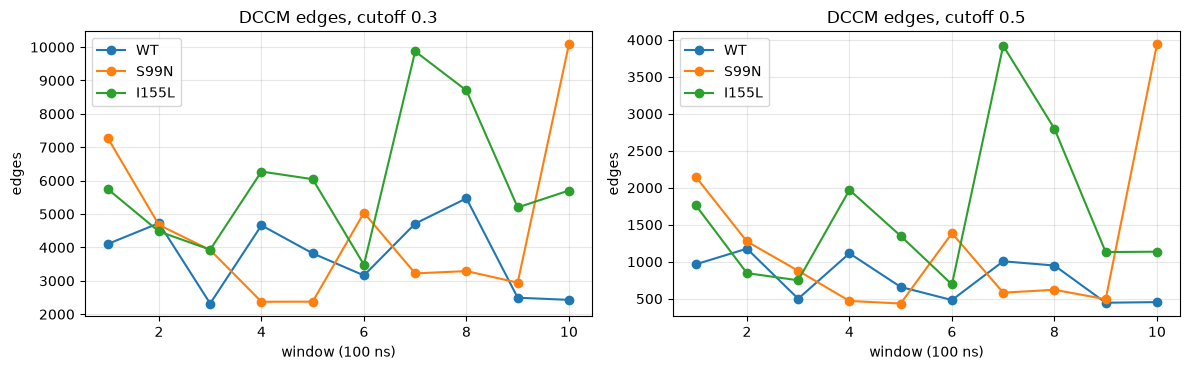

variant          occupancy spread           DCCM(0.3) spread
WT                          1.09x                      2.36x
S99N                        1.03x                      4.25x
I155L                       1.07x                      2.84x

If the DCCM column is much larger than the occupancy column, the correlation estimate is window-length-limited — see 10.1.


In [22]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
ks = range(1, N_WINDOWS+1)
for v in VARIANTS:
    ax[0].plot(ks, [dccm_results[v][k]["loose"].number_of_edges() for k in ks],
               "o-", label=v)
    ax[1].plot(ks, [dccm_results[v][k]["tight"].number_of_edges() for k in ks],
               "o-", label=v)
ax[0].set_title("DCCM edges, cutoff 0.3"); ax[1].set_title("DCCM edges, cutoff 0.5")
for a in ax:
    a.set_xlabel(f"window ({WINDOW_NS} ns)"); a.set_ylabel("edges")
    a.grid(alpha=0.3); a.legend()
plt.tight_layout(); savefig("10_dccm", "dccm_stability_all"); plt.show()

# scale check: how jumpy is DCCM relative to occupancy?
def spread(counts):
    '''max/min edge count across windows. A window with no edges makes the
    ratio undefined, which is itself the finding.'''
    return f"{max(counts)/min(counts):.2f}x" if min(counts) > 0 else "undefined (empty window)"

print(f"{'variant':8s} {'occupancy spread':>24s} {'DCCM(0.3) spread':>26s}")
for v in VARIANTS:
    og, _ = occ_results[v]
    oe = [og[k].number_of_edges() for k in ks]
    de = [dccm_results[v][k]["loose"].number_of_edges() for k in ks]
    print(f"{v:8s} {spread(oe):>24s} {spread(de):>26s}")
print("\nIf the DCCM column is much larger than the occupancy column, the "
      "correlation estimate is window-length-limited — see 10.1.")

---
## 11. The hybrid network

An edge survives only where the two residues make a **persistent physical contact**
*and* **move in a correlated manner** in the same window — the strict intersection.

$$E_h = \{\,\{i,j\} : W_{ij} \ge \theta_h \ \text{and}\ |R_{ij}| \ge c\,\}
\qquad w_h = \sqrt{W_{ij}\cdot|R_{ij}|}$$

This is the construction closest to Sethi et al.: contacts determine the edge set,
correlation determines the weight. [ref 5] Here `theta_h = 0.75` matches their >75%
frame-occupancy criterion directly.

The geometric-mean weight is **from the mentor's tracker**. Sethi's own convention is
`-log|C_ij|` as a distance, which the `distance` attribute below provides.

**The hybrid inherits the DCCM's convergence limitation** through its correlation term.
If section 10.1 came back below 0.85, treat the hybrid with the same caution.

In [23]:
def build_hybrid_variant(variant, theta_h=THETA_HYB, corr_cut=CORR_CUTS["loose"],
                         n_windows=N_WINDOWS):
    _, occs = occ_results[variant]
    mats    = conv[variant]["matrices"]
    _, resnums = coords[variant]

    graphs = {}
    print(f"\n{variant}  (theta_h={theta_h}, |R|>={corr_cut})")
    for k in range(1, n_windows + 1):
        W, R = occs[k], mats[k]
        G = nx.Graph()
        G.add_nodes_from(int(r) for r in resnums)
        for i, j in zip(*np.triu_indices(len(resnums), k=1)):
            if W[i, j] >= theta_h and abs(R[i, j]) >= corr_cut:
                s = float(np.sqrt(W[i, j] * abs(R[i, j])))
                _add_weighted_edge(G, resnums[i], resnums[j], s,
                                   extra={"occupancy": float(W[i, j]),
                                          "corr": float(R[i, j])})
        graphs[k] = G
        giant = len(max(nx.connected_components(G), key=len))
        print(f"  w{k:02d}: {G.number_of_edges():4d} edges  giant {giant:3d}/{N_RES}  "
              f"<k>={2*G.number_of_edges()/N_RES:5.2f}  "
              f"ridge {sum(1 for r in RIDGE if G.degree(r)>0):2d}/11  "
              f"mut {sum(1 for r in MUT_SITES if G.degree(r)>0)}/2")

    out = f"{OUTDIR}/{variant}_hybrid_graphs.pkl"
    with open(out, "wb") as f:
        pickle.dump({"variant": variant, "graphs": graphs, "resnums": resnums,
                     "theta_h": theta_h, "corr_cut": corr_cut}, f)
    print(f"  saved -> {out}")
    return graphs


hybrid_results = {v: build_hybrid_variant(v) for v in VARIANTS}


WT  (theta_h=0.75, |R|>=0.3)
  w01:  447 edges  giant 187/219  <k>= 4.08  ridge 11/11  mut 2/2
  w02:  447 edges  giant 189/219  <k>= 4.08  ridge 11/11  mut 2/2
  w03:  445 edges  giant 200/219  <k>= 4.06  ridge 11/11  mut 2/2
  w04:  464 edges  giant 201/219  <k>= 4.24  ridge 11/11  mut 2/2
  w05:  455 edges  giant 192/219  <k>= 4.16  ridge 11/11  mut 2/2
  w06:  445 edges  giant 194/219  <k>= 4.06  ridge 11/11  mut 2/2
  w07:  446 edges  giant 198/219  <k>= 4.07  ridge 11/11  mut 2/2
  w08:  469 edges  giant 198/219  <k>= 4.28  ridge 11/11  mut 2/2
  w09:  463 edges  giant 202/219  <k>= 4.23  ridge 11/11  mut 2/2
  w10:  447 edges  giant 190/219  <k>= 4.08  ridge 11/11  mut 2/2
  saved -> /Users/Ritwik/Desktop/Projects/graph_analysis/analysis/networks/WT_hybrid_graphs.pkl

S99N  (theta_h=0.75, |R|>=0.3)
  w01:  453 edges  giant 200/219  <k>= 4.14  ridge 11/11  mut 2/2
  w02:  458 edges  giant 195/219  <k>= 4.18  ridge 11/11  mut 2/2
  w03:  455 edges  giant 191/219  <k>= 4.16  ridge

  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/11_hybrid/graph_types_all.png


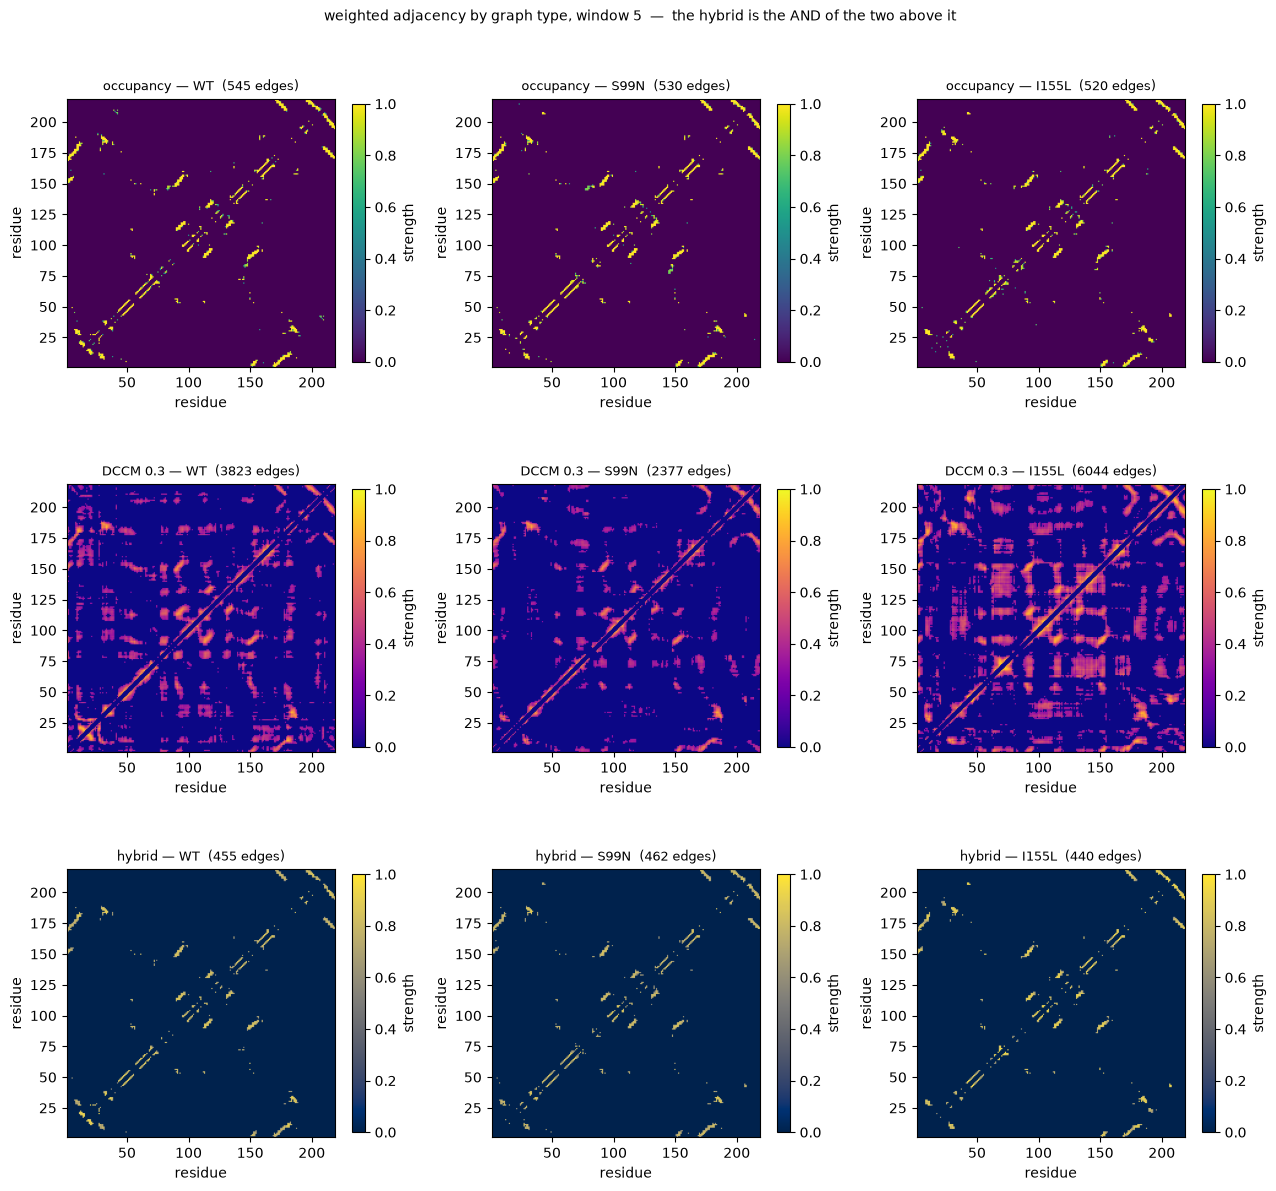

In [24]:
# the three graph types side by side, same window, every variant
k_mid = N_WINDOWS // 2
fig, ax = grid(3, len(VARIANTS))
for c, v in enumerate(VARIANTS):
    occ_g, _ = occ_results[v]
    rows = [(occ_g[k_mid],                        f"occupancy — {v}",  "viridis"),
            (dccm_results[v][k_mid]["loose"],     f"DCCM 0.3 — {v}",   "plasma"),
            (hybrid_results[v][k_mid],            f"hybrid — {v}",     "cividis")]
    for r, (G, title, cm) in enumerate(rows):
        M = nx.to_numpy_array(G, weight="weight")
        heat(ax[r][c], M, f"{title}  ({G.number_of_edges()} edges)",
             cmap=cm, vmin=0, vmax=1, label="strength")
fig.suptitle(f"weighted adjacency by graph type, window {k_mid}  —  "
             f"the hybrid is the AND of the two above it", y=1.005, fontsize=10)
plt.tight_layout(); savefig("11_hybrid", "graph_types_all"); plt.show()

---
## 12. Diagnostics

### 12.1 Ridge subgraph connectivity

Do the 11 ridge residues actually share edges with each other, or do they merely appear
grouped in a layout?

A connected ridge subgraph would be a real finding. Eleven isolated nodes would mean the
spring-layout picture is misleading — highly-connected nodes get pulled centrally by the
layout algorithm regardless of whether they form a unit.

**Either way this is not yet evidence.** The ridge residues were originally identified
*as* network hubs, so finding them hub-like is partly circular. The permutation tests
against random same-size residue sets are what decide it.


WT — occupancy
  w01:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]
  w05:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]
  w10:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]

WT — hybrid
  w01:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]
  w05:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]
  w10:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]

S99N — occupancy
  w01:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]
  w05:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]
  w10:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]

S99N — hybrid
  w01:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 164, 165, 168, 169]
  w05:  9 edges, 3 component(s), largest 8/11  [95, 137, 140, 160, 1

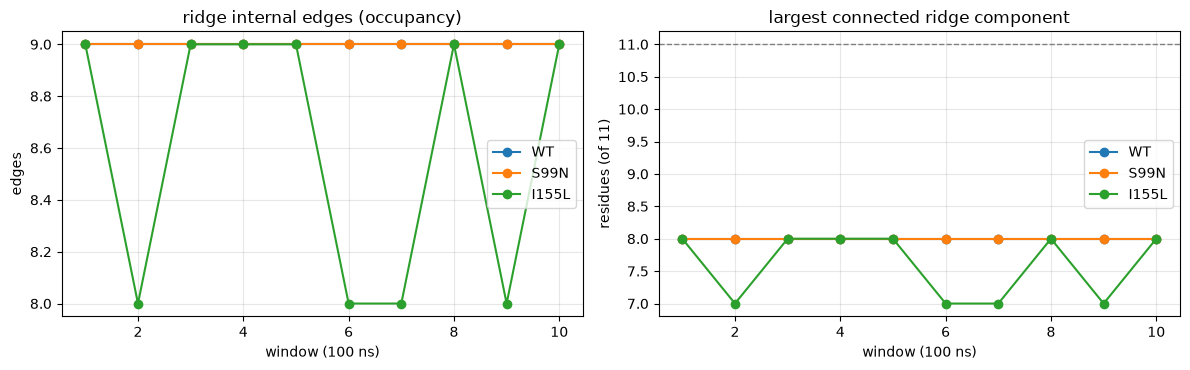

In [25]:
def ridge_subgraph_report(graphs, label):
    print(f"\n{label}")
    for k in (1, N_WINDOWS//2, N_WINDOWS):
        sub = graphs[k].subgraph(RIDGE)
        comps = sorted((sorted(c) for c in nx.connected_components(sub)),
                       key=len, reverse=True)
        print(f"  w{k:02d}: {sub.number_of_edges():2d} edges, {len(comps)} component(s), "
              f"largest {len(comps[0])}/11  {comps[0]}")

for v in VARIANTS:
    og, _ = occ_results[v]
    ridge_subgraph_report(og, f"{v} — occupancy")
    ridge_subgraph_report(hybrid_results[v], f"{v} — hybrid")

ks = range(1, N_WINDOWS + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharex=True)
for v in VARIANTS:
    og, _ = occ_results[v]
    ax[0].plot(ks, [og[k].subgraph(RIDGE).number_of_edges() for k in ks], "o-", label=v)
    ax[1].plot(ks, [len(max(nx.connected_components(og[k].subgraph(RIDGE)), key=len))
                    for k in ks], "o-", label=v)
ax[0].set_title("ridge internal edges (occupancy)")
ax[1].set_title("largest connected ridge component")
ax[1].axhline(len(RIDGE), color="grey", ls="--", lw=1)
for a in ax:
    a.set_xlabel(f"window ({WINDOW_NS} ns)"); a.grid(alpha=0.3); a.legend()
ax[0].set_ylabel("edges"); ax[1].set_ylabel(f"residues (of {len(RIDGE)})")
plt.tight_layout(); savefig("12_diagnostics", "ridge_subgraph"); plt.show()

### 12.2 Mutation-site neighbourhoods across variants

The first genuinely comparative quantity. If S99N or I155L rewires its local contact
environment relative to WT, it shows up here.

Still descriptive — a difference becomes a result only once it is compared against what
random residues do (permutation test, not yet implemented).

Occupancy networks, window 5

residue 99
  WT     degree  6  neighbours [95, 96, 102, 103, 156, 157]
  S99N   degree  6  neighbours [95, 96, 102, 103, 156, 157]
  I155L  degree  7  neighbours [95, 96, 102, 103, 155, 156, 157]
  S99N vs WT:  gained []  lost []
  I155L vs WT:  gained [155]  lost []

residue 155
  WT     degree  7  neighbours [4, 5, 6, 93, 94, 95, 161]
  S99N   degree  7  neighbours [4, 5, 6, 93, 94, 95, 161]
  I155L  degree  9  neighbours [4, 5, 6, 93, 94, 95, 96, 99, 161]
  S99N vs WT:  gained []  lost []
  I155L vs WT:  gained [96, 99]  lost []

  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/12_diagnostics/mutation_site_degree.png


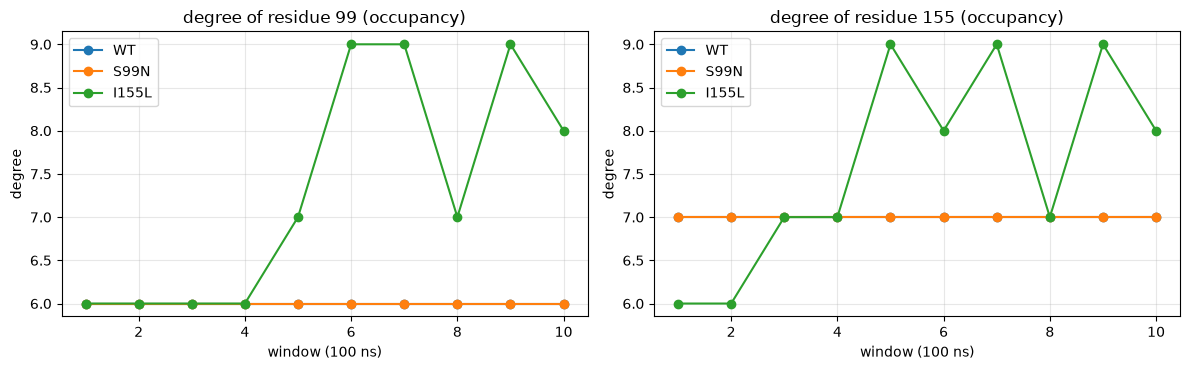

In [26]:
k_mid = N_WINDOWS // 2
print(f"Occupancy networks, window {k_mid}\n")
for site in MUT_SITES:
    print(f"residue {site}")
    nbrs = {}
    for v in VARIANTS:
        G, _ = occ_results[v]
        nbrs[v] = set(G[k_mid].neighbors(site))
        print(f"  {v:6s} degree {G[k_mid].degree(site):2d}  "
              f"neighbours {sorted(nbrs[v])}")
    if "WT" in VARIANTS:
        for v in VARIANTS:
            if v == "WT": continue
            print(f"  {v} vs WT:  gained {sorted(nbrs[v] - nbrs['WT'])}  "
                  f"lost {sorted(nbrs['WT'] - nbrs[v])}")
    print()

ks = range(1, N_WINDOWS + 1)
fig, ax = plt.subplots(1, len(MUT_SITES), figsize=(6*len(MUT_SITES), 3.8), squeeze=False)
for c, site in enumerate(MUT_SITES):
    for v in VARIANTS:
        og, _ = occ_results[v]
        ax[0][c].plot(ks, [og[k].degree(site) for k in ks], "o-", label=v)
    ax[0][c].set_title(f"degree of residue {site} (occupancy)")
    ax[0][c].set_xlabel(f"window ({WINDOW_NS} ns)"); ax[0][c].set_ylabel("degree")
    ax[0][c].grid(alpha=0.3); ax[0][c].legend()
plt.tight_layout(); savefig("12_diagnostics", "mutation_site_degree"); plt.show()

---
## 13. Network figures

Node position in a spring layout is **not interpretable** — a 2D projection settled at a
local energy minimum, which changes with the random seed. Use these to confirm the
networks are intact and ridge residues are not scattered, nothing more.

  figure -> /Users/Ritwik/Desktop/Projects/graph_analysis/figures/13_networks/networks_all_w05.png


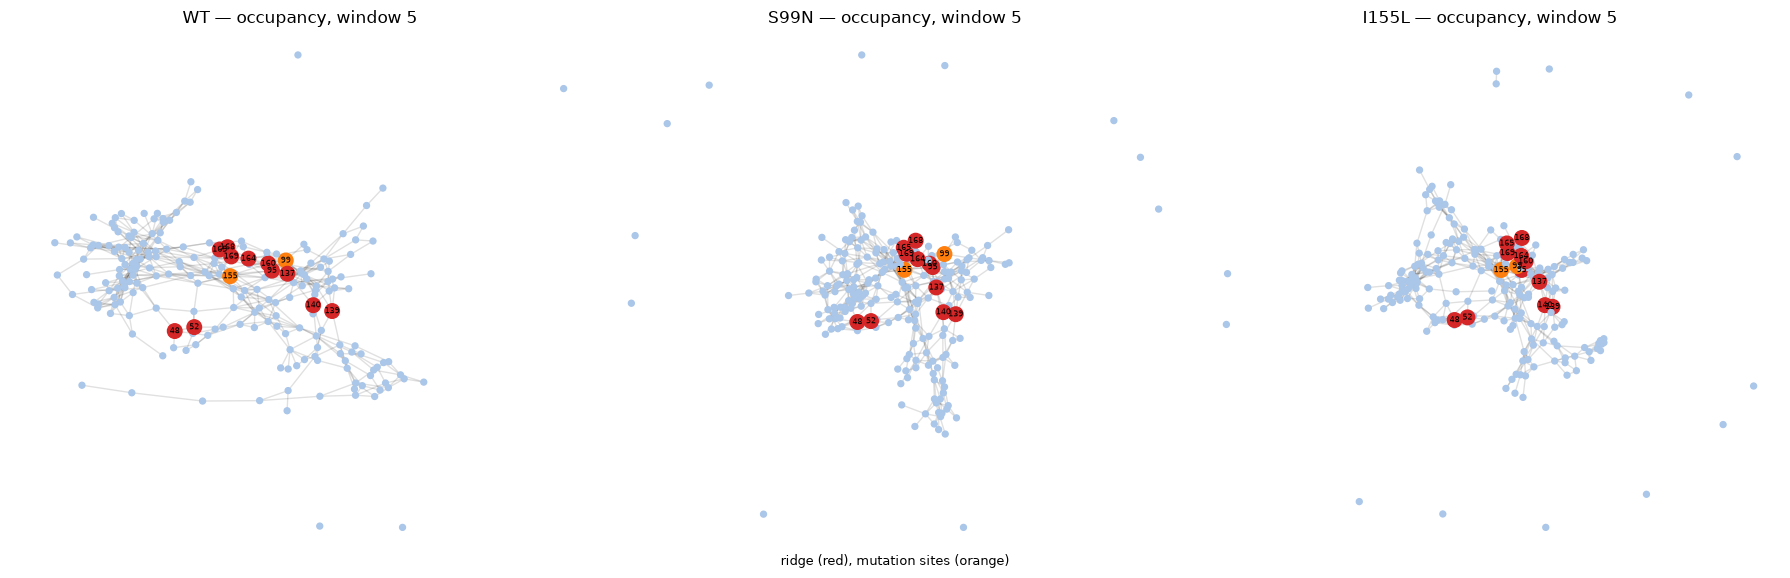

In [27]:
k_show = N_WINDOWS // 2
fig, axes = plt.subplots(1, len(VARIANTS), figsize=(6*len(VARIANTS), 6))
if len(VARIANTS) == 1:
    axes = [axes]

for ax, v in zip(axes, VARIANTS):
    graphs, _ = occ_results[v]
    G = graphs[k_show]
    pos = nx.spring_layout(G, seed=42, weight="weight")
    colors = ["#d62728" if n in RIDGE else "#ff7f0e" if n in MUT_SITES else "#aac6e8"
              for n in G.nodes()]
    sizes  = [110 if n in RIDGE or n in MUT_SITES else 18 for n in G.nodes()]
    nx.draw_networkx_edges(G, pos, alpha=0.12, ax=ax)
    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=sizes, ax=ax)
    nx.draw_networkx_labels(G, pos, labels={n: n for n in RIDGE + MUT_SITES},
                            font_size=6, ax=ax)
    ax.set_title(f"{v} — occupancy, window {k_show}"); ax.axis("off")

fig.suptitle("ridge (red), mutation sites (orange)", y=0.02, fontsize=9)
plt.tight_layout(); savefig("13_networks", f"networks_all_w{k_show:02d}")
plt.show()

---
## 14. Next

- [ ] **Active-site and NADPH-site residue lists** — blocks Act III entirely; needed from mentor, with the numbering convention stated
- [ ] **Confirm the ridge numbering convention** — MET at resSeq 95 implies the Muzata candidates are already in construct numbering and need no shift, but the paper's methods should confirm it
- [ ] Null models: degree-preserving rewiring that keeps (i,i+1) chain connectivity [ref 7]
- [ ] Permutation tests: ridge vs random same-size residue sets
- [ ] Shortest-path analysis, mutation sites → functional core (use the `distance` attribute, not `weight`)

### Known limitations to raise with the mentor

**Cα-only cannot do Objective 2.** The network sees backbone positions. S99N swaps a
hydroxyl for an amide; the Cα does not move, so WT and S99N are identical at residue 99
in this representation. Contacts gained and lost per mutant requires a heavy-atom
network (~1700 atoms per frame instead of 219, roughly 60× the distance computation).
Sethi's own criterion is heavy-atom at 4.5 Å for exactly this reason. [ref 5,6]

**Three thresholds, not one.** `theta` for contacts, `c` for correlation, `theta_h` for
the hybrid's stricter contact requirement. They threshold different matrices measuring
different things. Collapsing them in notes is an easy source of later confusion.

**The 0.3 correlation cutoff has no paper behind it.** See §1.1. It is a Bio3D default
the Grant lab explicitly describes as system-dependent, not a value from Sethi et al.